# Logistic regression from scratch with NumPy

This is a **learning notebook**. It exposes the calculations that scikit-learn normally performs inside `fit`:

```text
features → linear score z → sigmoid probability p → log loss → gradients → coefficient updates
```

We use the same ten Home Credit features and the same time split as the baseline. To keep gradient descent quick enough to study interactively, this notebook uses a reproducible sample from the training and validation periods. The professional model should continue using scikit-learn on the full data.

By the end, you will understand:

- what the intercept and coefficients store;
- why the linear score is the log-odds;
- how sigmoid creates a probability;
- how log loss measures prediction error;
- how gradients tell us which direction to change parameters;
- how gradient descent learns the parameters;
- how our implementation compares with scikit-learn.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.set_printoptions(precision=4, suppress=True)

## 2. Locate the data and select the ten source features

The custom code below implements the **model learning algorithm**. We still use tested library classes for median imputation and scaling, because those are preprocessing operations rather than logistic-regression optimization.

In [2]:
possible_roots = [Path.cwd(), Path.cwd().parent]
project_dir = next(
    path for path in possible_roots
    if (path / "data" / "parquet_files" / "train" / "train_base.parquet").exists()
)
train_dir = project_dir / "data" / "parquet_files" / "train"

features = [
    "credamount_770A",
    "annuity_780A",
    "maininc_215A",
    "applications30d_658L",
    "numactivecreds_622L",
    "totaldebt_9A",
    "avgdbddpdlast24m_3658932P",
    "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L",
    "price_1097A",
]

print("Project directory:", project_dir)
print("Source features:", len(features))

Project directory: D:\Home Credit - Credit Risk Model Stability
Source features: 10


## 3. Load, join and make the time split

In [3]:
base_df = pd.read_parquet(
    train_dir / "train_base.parquet",
    columns=["case_id", "WEEK_NUM", "target"],
)

static_df = pd.concat(
    [
        pd.read_parquet(
            train_dir / f"train_static_0_{part}.parquet",
            columns=["case_id", *features],
        )
        for part in (0, 1)
    ],
    ignore_index=True,
)

df = base_df.merge(static_df, on="case_id", validate="one_to_one")
train_period = df.loc[df["WEEK_NUM"].between(0, 51)]
validation_period = df.loc[df["WEEK_NUM"].between(52, 71)]

print(f"All joined rows: {len(df):,}")
print(f"Training-period rows: {len(train_period):,}")
print(f"Validation-period rows: {len(validation_period):,}")

All joined rows: 1,526,659
Training-period rows: 1,065,921
Validation-period rows: 248,535


## 4. Create reproducible learning samples

Full-batch gradient descent reads every selected training row once per iteration. A sample makes the internal loop fast enough to inspect. The time boundary remains correct: training examples come only from weeks 0–51 and validation examples only from weeks 52–71.

In [4]:
train_sample = train_period.sample(
    n=min(100_000, len(train_period)),
    random_state=RANDOM_STATE,
)
validation_sample = validation_period.sample(
    n=min(50_000, len(validation_period)),
    random_state=RANDOM_STATE,
)

X_train_raw = train_sample[features]
y_train = train_sample["target"].to_numpy(dtype=np.float64)
X_validation_raw = validation_sample[features]
y_validation = validation_sample["target"].to_numpy(dtype=np.float64)

print(f"Learning training rows: {len(y_train):,}")
print(f"Learning validation rows: {len(y_validation):,}")
print(f"Training default rate: {y_train.mean():.4%}")
print(f"Validation default rate: {y_validation.mean():.4%}")

Learning training rows: 100,000
Learning validation rows: 50,000
Training default rate: 3.0520%
Validation default rate: 4.1220%


## 5. Prepare the numerical matrix

The imputer and scaler are fitted **only on the training sample**:

1. Missing values are replaced with training medians.
2. Missing indicators are appended where needed.
3. Every resulting column is standardized using its training mean and standard deviation.

The ten source features become more than ten prepared inputs because missing indicators are additional model inputs.

In [5]:
imputer = SimpleImputer(strategy="median", add_indicator=True)
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train_raw)
X_train = scaler.fit_transform(X_train_imputed).astype(np.float64)

X_validation_imputed = imputer.transform(X_validation_raw)
X_validation = scaler.transform(X_validation_imputed).astype(np.float64)

print("Raw source columns:", X_train_raw.shape[1])
print("Prepared model inputs:", X_train.shape[1])
print("Training matrix shape:", X_train.shape)
print("Validation matrix shape:", X_validation.shape)
print("Remaining missing values:", np.isnan(X_train).sum())

Raw source columns: 10
Prepared model inputs: 14
Training matrix shape: (100000, 14)
Validation matrix shape: (50000, 14)
Remaining missing values: 0


## 6. The mathematical pieces

For application \(i\), logistic regression calculates:

\[
z_i = b + x_i^T w
\]

The sigmoid converts that unrestricted score into a probability:

\[
p_i = rac{1}{1 + e^{-z_i}}
\]

The same relationship can be rearranged as:

\[
z_i = \log\left(rac{p_i}{1-p_i}ight)
\]

Therefore, the linear score \(z\) is exactly the **log-odds**. Odds are not an extra prediction step.

Binary log loss over \(m\) applications is:

\[
J(w,b)=-rac{1}{m}\sum_i\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)ight]
\]

Its gradients are:

\[
rac{\partial J}{\partial w}=rac{1}{m}X^T(p-y),
\qquad
rac{\partial J}{\partial b}=rac{1}{m}\sum_i(p_i-y_i)
\]

Gradient descent updates in the opposite direction of the gradients:

\[
w \leftarrow w-lpharac{\partial J}{\partial w},
\qquad
b \leftarrow b-lpharac{\partial J}{\partial b}
\]

Here, \(lpha\) is the learning rate.

## 7. Implement sigmoid and log loss

In [6]:
def sigmoid(z):
    # Clipping prevents overflow in exp for extremely large scores.
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def binary_log_loss(y_true, probability):
    # Clipping prevents log(0), which is undefined.
    probability = np.clip(probability, 1e-15, 1 - 1e-15)
    return -np.mean(
        y_true * np.log(probability)
        + (1 - y_true) * np.log(1 - probability)
    )


example_scores = np.array([-4.0, -3.0, -2.0, 0.0, 2.0])
pd.DataFrame({
    "linear_score_z": example_scores,
    "odds_exp_z": np.exp(example_scores),
    "probability_sigmoid_z": sigmoid(example_scores),
})

,linear_score_z,odds_exp_z,probability_sigmoid_z
0,-4.0,0.018316,0.017986
1,-3.0,0.049787,0.047426
2,-2.0,0.135335,0.119203
3,0.0,1.000000,0.500000
4,2.0,7.389056,0.880797


## 8. Inspect one gradient-descent step

Before creating a class, perform one update explicitly. Initializing the intercept with the training base rate gives a sensible starting probability. Coefficients start at zero, so every row initially receives that same probability.

In [7]:
number_of_rows, number_of_inputs = X_train.shape
weights = np.zeros(number_of_inputs)

base_rate = np.clip(y_train.mean(), 1e-15, 1 - 1e-15)
intercept = np.log(base_rate / (1 - base_rate))

initial_scores = X_train @ weights + intercept
initial_probabilities = sigmoid(initial_scores)
initial_loss = binary_log_loss(y_train, initial_probabilities)

errors = initial_probabilities - y_train
weight_gradient = X_train.T @ errors / number_of_rows
intercept_gradient = errors.mean()

learning_rate = 0.1
updated_weights = weights - learning_rate * weight_gradient
updated_intercept = intercept - learning_rate * intercept_gradient

print(f"Initial intercept: {intercept:.6f}")
print(f"Initial probability for every row: {initial_probabilities[0]:.6f}")
print(f"Initial log loss: {initial_loss:.6f}")
print("First five weight gradients:", weight_gradient[:5])
print(f"Intercept gradient: {intercept_gradient:.8f}")
print("First five updated weights:", updated_weights[:5])

Initial intercept: -3.458378
Initial probability for every row: 0.030520
Initial log loss: 0.136545
First five weight gradients: [-0.0034 -0.0025  0.0023 -0.0064 -0.0002]
Intercept gradient: -0.00000000
First five updated weights: [ 0.0003  0.0002 -0.0002  0.0006  0.    ]


## 9. Build logistic regression from scratch

This class deliberately keeps the algorithm visible. It implements full-batch gradient descent and optional L2 regularization. The intercept is not regularized.

In [8]:
class NumpyLogisticRegression:
    def __init__(self, learning_rate=0.1, iterations=600, l2_strength=0.0, log_every=25):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l2_strength = l2_strength
        self.log_every = log_every

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _log_loss(y, p):
        p = np.clip(p, 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64)
        number_of_rows, number_of_inputs = X.shape

        self.coef_ = np.zeros(number_of_inputs, dtype=np.float64)
        base_rate = np.clip(y.mean(), 1e-15, 1 - 1e-15)
        self.intercept_ = float(np.log(base_rate / (1 - base_rate)))
        self.history_ = []

        for iteration in range(self.iterations + 1):
            scores = X @ self.coef_ + self.intercept_
            probabilities = self._sigmoid(scores)

            if iteration % self.log_every == 0 or iteration == self.iterations:
                data_loss = self._log_loss(y, probabilities)
                penalty = 0.5 * self.l2_strength * np.sum(self.coef_ ** 2)
                self.history_.append({
                    "iteration": iteration,
                    "loss": data_loss + penalty,
                })

            if iteration == self.iterations:
                break

            errors = probabilities - y
            weight_gradient = (
                X.T @ errors / number_of_rows
                + self.l2_strength * self.coef_
            )
            intercept_gradient = errors.mean()

            self.coef_ -= self.learning_rate * weight_gradient
            self.intercept_ -= self.learning_rate * intercept_gradient

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.coef_ + self.intercept_

    def predict_proba(self, X):
        default_probability = self._sigmoid(self.decision_function(X))
        return np.column_stack([1 - default_probability, default_probability])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

## 10. Train the custom model

This is where our visible loop replaces scikit-learn's `fit` internals. We initially use no L2 penalty so comparison with an unregularized scikit-learn model is easier.

In [9]:
custom_model = NumpyLogisticRegression(
    learning_rate=0.2,
    iterations=600,
    l2_strength=0.0,
    log_every=20,
)
custom_model.fit(X_train, y_train)

training_history = pd.DataFrame(custom_model.history_)
training_history.tail()

,iteration,loss
26,520,0.134966
27,540,0.134965
28,560,0.134964
29,580,0.134963
30,600,0.134962


## 11. Plot the optimization history

This graph is not part of prediction. It is a diagnostic showing whether gradient descent is reducing the objective. A decreasing curve means the updates are moving in a useful direction.

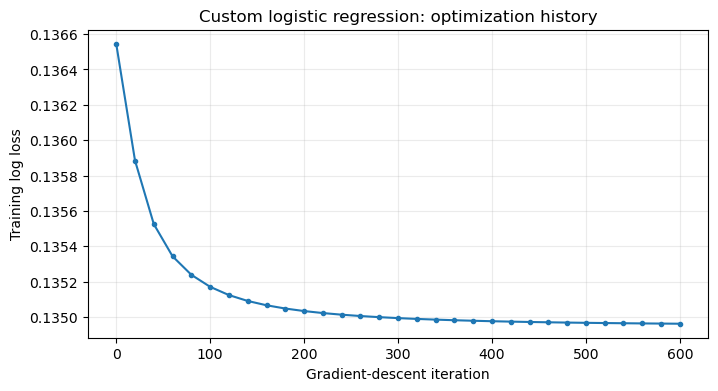

Starting loss: 0.136545
Final loss:    0.134962


In [10]:
plt.figure(figsize=(8, 4))
plt.plot(training_history["iteration"], training_history["loss"], marker="o", markersize=3)
plt.xlabel("Gradient-descent iteration")
plt.ylabel("Training log loss")
plt.title("Custom logistic regression: optimization history")
plt.grid(alpha=0.25)
plt.show()

print("Starting loss:", f"{training_history['loss'].iloc[0]:.6f}")
print("Final loss:   ", f"{training_history['loss'].iloc[-1]:.6f}")

## 12. Evaluate probabilities on later weeks

In [11]:
custom_validation_probability = custom_model.predict_proba(X_validation)[:, 1]

custom_auc = roc_auc_score(y_validation, custom_validation_probability)
custom_ap = average_precision_score(y_validation, custom_validation_probability)
custom_log_loss = log_loss(y_validation, custom_validation_probability)

pd.Series({
    "Validation applications": len(y_validation),
    "Actual default rate": y_validation.mean(),
    "Mean predicted probability": custom_validation_probability.mean(),
    "ROC AUC": custom_auc,
    "Gini": 2 * custom_auc - 1,
    "Average precision": custom_ap,
    "Log loss": custom_log_loss,
})

Validation applications       50000.000000
Actual default rate               0.041220
Mean predicted probability        0.031652
ROC AUC                           0.607679
Gini                              0.215358
Average precision                 0.071246
Log loss                          0.170722
dtype: float64

## 13. Verify against scikit-learn

Both models use exactly the same prepared matrices and no regularization. They may not be numerically identical because they use different optimizers and stopping behavior, but their probabilities and metrics should be close if the custom implementation is correct.

In [12]:
library_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=1_000,
)
library_model.fit(X_train, y_train)
library_validation_probability = library_model.predict_proba(X_validation)[:, 1]

comparison = pd.DataFrame({
    "model": ["Custom NumPy", "scikit-learn"],
    "ROC AUC": [
        roc_auc_score(y_validation, custom_validation_probability),
        roc_auc_score(y_validation, library_validation_probability),
    ],
    "Average precision": [
        average_precision_score(y_validation, custom_validation_probability),
        average_precision_score(y_validation, library_validation_probability),
    ],
    "Log loss": [
        log_loss(y_validation, custom_validation_probability),
        log_loss(y_validation, library_validation_probability),
    ],
})

probability_difference = np.abs(
    custom_validation_probability - library_validation_probability
)

display(comparison)
print("Mean absolute probability difference:", f"{probability_difference.mean():.8f}")
print("Maximum absolute probability difference:", f"{probability_difference.max():.8f}")

,model,ROC AUC,Average precision,Log loss
0,Custom NumPy,0.607679,0.071246,0.170722
1,scikit-learn,0.607080,0.071018,0.170724


Mean absolute probability difference: 0.00061620
Maximum absolute probability difference: 0.02784191


## 14. Inspect learned parameters

Because the prepared inputs are standardized, coefficient magnitudes are more comparable. A positive coefficient increases predicted default log-odds when that prepared input increases; a negative coefficient decreases them. These are associations conditional on the other model inputs, not causal effects.

In [13]:
prepared_names = list(imputer.get_feature_names_out(features))

coefficient_comparison = pd.DataFrame({
    "prepared_input": prepared_names,
    "custom_coefficient": custom_model.coef_,
    "sklearn_coefficient": library_model.coef_[0],
})
coefficient_comparison["absolute_custom_coefficient"] = (
    coefficient_comparison["custom_coefficient"].abs()
)

print("Custom intercept:", f"{custom_model.intercept_:.6f}")
print("scikit-learn intercept:", f"{library_model.intercept_[0]:.6f}")
coefficient_comparison.sort_values(
    "absolute_custom_coefficient",
    ascending=False,
).drop(columns="absolute_custom_coefficient")

Custom intercept: -3.489889
scikit-learn intercept: -3.494336


,prepared_input,custom_coefficient,sklearn_coefficient
3,applications30d_658L,0.137220,0.137841
2,maininc_215A,-0.092112,-0.093395
7,avgdpdtolclosure24_3658938P,0.087523,0.103847
0,credamount_770A,0.079152,0.108071
5,totaldebt_9A,0.077064,0.084226
11,missingindicator_avgdbddpdlast24m_3658932P,0.054305,0.072795
6,avgdbddpdlast24m_3658932P,0.040028,0.026499
8,clientscnt12m_3712952L,0.035598,0.035531
13,missingindicator_price_1097A,-0.027731,-0.035084
10,missingindicator_maininc_215A,-0.023028,-0.040140


## 15. Manually reproduce one prediction

This proves that prediction is only a dot product, an intercept, and sigmoid.

In [14]:
row_number = 0
one_row = X_validation[row_number]

manual_z = custom_model.intercept_ + np.sum(one_row * custom_model.coef_)
manual_odds = np.exp(manual_z)
manual_probability = 1.0 / (1.0 + np.exp(-manual_z))
method_probability = custom_model.predict_proba(one_row.reshape(1, -1))[0, 1]

pd.Series({
    "actual target": y_validation[row_number],
    "linear score z / log-odds": manual_z,
    "odds = exp(z)": manual_odds,
    "manual sigmoid probability": manual_probability,
    "predict_proba result": method_probability,
})

actual target                 0.000000
linear score z / log-odds    -3.230100
odds = exp(z)                 0.039554
manual sigmoid probability    0.038049
predict_proba result          0.038049
dtype: float64

## What you should be able to explain now

1. The **features are data**; the coefficients and intercept are **parameters learned from data**.
2. `fit` repeatedly performs forward calculation, loss calculation, gradient calculation and parameter updates.
3. \(z=Xw+b\) is both the linear score and the predicted log-odds.
4. `sigmoid(z)` is the predicted probability of `target = 1`.
5. Log loss strongly penalizes confident wrong probabilities.
6. The gradient is the direction of fastest loss increase, so gradient descent moves in the opposite direction.
7. Preprocessing and time-aware evaluation remain essential even when the learning algorithm is implemented correctly.
8. The NumPy implementation is educational. The tested, optimized scikit-learn implementation remains the correct choice for the full professional pipeline.

### Good experiments

- Change the learning rate to `0.01`, `0.5` and `2.0`; observe the loss curve.
- Change the number of iterations and see when improvement becomes small.
- Set `l2_strength` to a small positive value and observe coefficient shrinkage.
- Remove scaling and observe how optimization behavior changes.
- Change the classification threshold, while remembering that it does not retrain the probability model.